# Tarea: correlación y regresión

Matemáticas para la Computación. Bryan Ezequiel Violante Arriaga.

Los datos son los anuncios de Airbnb en la Ciudad de México del corte del 23 de septiembre de 2026 de Inside Airbnb, el mismo del proyecto 2. La variable respuesta es el precio por noche que anuncia cada anfitrión.

**El objetivo es explicar, no predecir.** La pregunta es cuánto se mueve el precio con el tamaño del alojamiento, con su ubicación y con su calificación, cada uno manteniendo fijos los otros dos. Eso decide casi todo lo demás: se buscan predictores poco correlacionados entre sí para que cada $\beta$ se pueda leer por separado, se revisan los residuos para que los errores estándar sean creíbles, y se prefiere un modelo con pocas variables interpretables a uno con muchas que prediga un poco mejor. Al final hay una partición de prueba, pero solo para comprobar que el ajuste no es un accidente de la muestra.

Los pasos de la tarea:

1. Correlación entre las variables independientes.
2. Selección de tres variables poco correlacionadas entre ellas.
3. Gráfica de dispersión de cada una contra la respuesta.
4. Un modelo lineal posible.
5. Residuos y ajuste del modelo.

Al final va el entregable: ecuación, $\beta$ estimados, $R^2$ y error, diagnóstico, una gráfica y límites de la interpretación.

In [1]:
import itertools
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

# Corte de septiembre de 2026 del proyecto 2, el que usa su analisis
ARCHIVO = Path("../proyecto2/data/2026-09-23/listings.csv.gz")
RUTA_FIGURAS = Path("figuras")

# Rango de precio por noche que el proyecto 2 considera plausible
PRECIO_MIN, PRECIO_MAX = 100, 50_000

# Centro de referencia, el Angel de la Independencia, y radio terrestre
CENTRO_LAT, CENTRO_LON = 19.4270, -99.1677
RADIO_TIERRA_KM = 6371

# Dos predictores cuentan como poco correlacionados si |rho| < UMBRAL
UMBRAL = 0.3

# Semilla de la particion entrenamiento / prueba
SEMILLA = 2026

AZUL, NARANJA = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
RUTA_FIGURAS.mkdir(exist_ok=True)

## Datos

Se lee el corte y se arman las once candidatas a variable independiente: todas las numéricas que tienen sentido para el precio. Dos son derivadas:

- `distancia`: kilómetros en línea recta al Ángel de la Independencia, con la fórmula del haversine. Es la misma que usa el proyecto 2.
- `banos`: número de baños sacado del texto de `bathrooms_text`, porque en este corte la columna `bathrooms` viene vacía. "Half-bath" cuenta como 0.5.

El precio se queda entre 100 y 50,000 pesos por noche, el rango que el proyecto 2 considera plausible; afuera hay errores de captura y anuncios de lujo extremo que no representan el mercado.

In [2]:
def distancia_km(latitud, longitud):
    """
    Distancia en linea recta de cada punto al centro de referencia.
    Usa la formula del haversine; a la escala de una ciudad el error
    frente al elipsoide es despreciable

    Inputs:
    -------
    latitud: Serie de latitudes en grados
    longitud: Serie de longitudes en grados

    Returns:
    -------
    Series: Distancias en kilometros

    """
    lat, lon = np.radians(latitud), np.radians(longitud)
    lat0, lon0 = np.radians(CENTRO_LAT), np.radians(CENTRO_LON)
    a = (np.sin((lat - lat0) / 2) ** 2
         + np.cos(lat0) * np.cos(lat) * np.sin((lon - lon0) / 2) ** 2)
    return 2 * RADIO_TIERRA_KM * np.arcsin(np.sqrt(a))


crudo = pd.read_csv(ARCHIVO, low_memory=False)
precio = crudo["price"].str.replace(r"[$,]", "", regex=True).astype(float)
texto_bano = crudo["bathrooms_text"].str.lower()
banos = texto_bano.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)
banos = banos.mask(banos.isna() & texto_bano.str.contains("half"), 0.5)

# Candidatas a variable independiente: numericas y con sentido para el
# precio. Las de texto, ids y fechas quedan fuera
anuncios = pd.DataFrame({
    "precio": precio,
    "capacidad": crudo["accommodates"],
    "recamaras": crudo["bedrooms"],
    "camas": crudo["beds"],
    "banos": banos,
    "distancia": distancia_km(crudo["latitude"], crudo["longitude"]),
    "calificacion": crudo["review_scores_rating"],
    "resenas": crudo["number_of_reviews"],
    "disponibilidad": crudo["availability_365"],
    "noches_min": crudo["minimum_nights"],
    "anuncios_anfitrion": crudo["host_listings_count"],
    "antig_anfitrion": crudo["hosts_time_as_host_years"],
    "host_id": crudo["host_id"],
})
CANDIDATAS = list(anuncios.columns[1:-1])

con_precio = anuncios[anuncios["precio"].between(PRECIO_MIN, PRECIO_MAX)].copy()
con_precio["log_precio"] = np.log(con_precio["precio"])
print(f"anuncios en el corte: {len(anuncios):,}")
print(f"con precio: {anuncios['precio'].notna().sum():,}")
print(f"con precio entre {PRECIO_MIN} y {PRECIO_MAX:,} pesos: "
      f"{len(con_precio):,}")
display(con_precio[CANDIDATAS].isna().mean().mul(100).round(1)
        .rename("% faltante").to_frame().T)

anuncios en el corte: 30,468
con precio: 28,360
con precio entre 100 y 50,000 pesos: 28,323


,capacidad,recamaras,camas,banos,distancia,calificacion,resenas,disponibilidad,noches_min,anuncios_anfitrion,antig_anfitrion
% faltante,0.0,0.1,1.4,0.1,0.0,12.6,0.0,0.0,0.0,0.0,0.0


## Paso 1: correlación entre las variables independientes

Se usa Spearman como medida principal porque casi todas las variables tienen colas largas (reseñas, noches mínimas, anuncios por anfitrión) y Pearson se deja arrastrar por unos cuantos valores extremos. Pearson va abajo, para comparar.

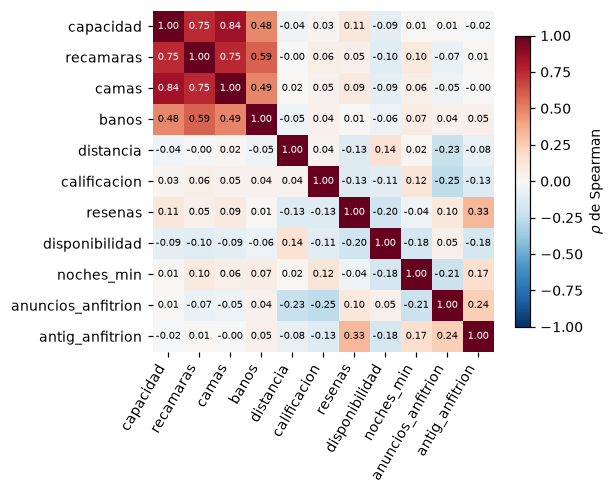

Pearson, para comparar:


,capacidad,recamaras,camas,banos,distancia,calificacion,resenas,disponibilidad,noches_min,anuncios_anfitrion,antig_anfitrion
capacidad,1.00,0.71,0.78,0.51,-0.02,0.03,0.03,-0.02,-0.01,0.08,0.01
recamaras,0.71,1.00,0.75,0.64,-0.00,0.03,-0.02,-0.03,0.01,0.04,0.03
camas,0.78,0.75,1.00,0.58,0.02,0.01,0.01,-0.01,-0.00,0.03,0.02
banos,0.51,0.64,0.58,1.00,-0.02,-0.00,-0.05,-0.01,0.01,0.07,0.03
distancia,-0.02,-0.00,0.02,-0.02,1.00,-0.01,-0.11,0.10,0.01,-0.16,-0.07
calificacion,0.03,0.03,0.01,-0.00,-0.01,1.00,0.09,-0.09,0.01,-0.07,-0.01
resenas,0.03,-0.02,0.01,-0.05,-0.11,0.09,1.00,-0.07,-0.05,0.07,0.27
disponibilidad,-0.02,-0.03,-0.01,-0.01,0.10,-0.09,-0.07,1.00,-0.00,0.08,-0.15
noches_min,-0.01,0.01,-0.00,0.01,0.01,0.01,-0.05,-0.00,1.00,-0.02,0.05
anuncios_anfitrion,0.08,0.04,0.03,0.07,-0.16,-0.07,0.07,0.08,-0.02,1.00,0.13


In [3]:
spearman = con_precio[CANDIDATAS].corr(method="spearman")
pearson = con_precio[CANDIDATAS].corr(method="pearson")

fig, eje = plt.subplots(figsize=(5.6, 4.7))
imagen = eje.imshow(spearman, cmap="RdBu_r", vmin=-1, vmax=1)
eje.set_xticks(range(len(CANDIDATAS)), CANDIDATAS, rotation=60,
               ha="right")
eje.set_yticks(range(len(CANDIDATAS)), CANDIDATAS)
for i, j in itertools.product(range(len(CANDIDATAS)), repeat=2):
    valor = spearman.iloc[i, j]
    eje.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=6.5,
             color="white" if abs(valor) > 0.6 else "black")
eje.spines[:].set_visible(False)
fig.colorbar(imagen, ax=eje, shrink=0.8, label=r"$\rho$ de Spearman")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "Correlacion.pdf", bbox_inches="tight")
plt.show()

print("Pearson, para comparar:")
display(pearson.round(2))

Se ve un bloque claro: **capacidad, recámaras y camas miden lo mismo**, el tamaño del alojamiento, con $\rho$ entre 0.75 y 0.84, y los baños se les pegan con 0.48 a 0.59. Meter dos de ellas al modelo infla los errores estándar y vuelve imposible separar sus efectos. Fuera de ese bloque todo está poco correlacionado. El único par que pasa de 0.3 es reseñas con antigüedad del anfitrión (0.33), que tiene sentido: un anfitrión con más tiempo acumula más reseñas. Le siguen calificación con anuncios del anfitrión (-0.25): los anfitriones con muchos anuncios, casi siempre administradores profesionales, tienen calificaciones algo más bajas.

## Paso 2: selección de tres variables

En lugar de escoger a ojo, se prueban todas las ternas posibles. Una terna es válida si **todos sus pares** tienen $|\rho| < 0.3$; entre las válidas se ordena por qué tan asociadas están sus variables con $\log(\text{precio})$. Se usa el logaritmo del precio porque el precio tiene una cola larga a la derecha y, como se ve más abajo, el modelo funciona mejor en esa escala.

In [4]:
con_y = (con_precio[CANDIDATAS]
         .corrwith(con_precio["log_precio"], method="spearman"))
display(con_y.round(3).sort_values(key=abs, ascending=False)
        .rename("rho con log(precio)").to_frame())

ternas = []
for terna in itertools.combinations(CANDIDATAS, 3):
    peor = max(abs(spearman.loc[a, b])
               for a, b in itertools.combinations(terna, 2))
    if peor < UMBRAL:
        ternas.append({"terna": ", ".join(terna),
                       "max |rho| entre ellas": round(peor, 3),
                       "suma |rho| con y": round(con_y[list(terna)]
                                                 .abs().sum(), 3)})
ternas = (pd.DataFrame(ternas)
          .sort_values("suma |rho| con y", ascending=False)
          .reset_index(drop=True))
print(f"ternas con todos sus pares por debajo de {UMBRAL}: "
      f"{len(ternas)} de {len(list(itertools.combinations(CANDIDATAS, 3)))}")
display(ternas.head(6))

,rho con log(precio)
capacidad,0.561
recamaras,0.493
camas,0.454
banos,0.387
distancia,-0.283
calificacion,0.152
anuncios_anfitrion,0.112
disponibilidad,-0.063
resenas,-0.034
noches_min,-0.023


ternas con todos sus pares por debajo de 0.3: 110 de 165


,terna,max |rho| entre ellas,suma |rho| con y
0,"capacidad, distancia, calificacion",0.039,0.996
1,"capacidad, distancia, anuncios_anfitrion",0.226,0.956
2,"recamaras, distancia, calificacion",0.059,0.929
3,"capacidad, distancia, disponibilidad",0.141,0.907
4,"camas, distancia, calificacion",0.046,0.890
5,"recamaras, distancia, anuncios_anfitrion",0.226,0.888


La mejor terna es **capacidad, distancia y calificación**. Cada una viene de un grupo distinto (tamaño, ubicación y calidad percibida) y la correlación más alta entre ellas es de 0.04: prácticamente independientes. Es justo lo que pide un modelo para explicar.

Al exigir calificación se pierden los anuncios sin reseñas, que no tienen calificación. Se cuenta abajo cuántos quedan. Los VIF (factor de inflación de la varianza) confirman que no hay colinealidad: un VIF de 1 quiere decir que la variable no se puede predecir con las otras dos.

In [5]:
PREDICTORES = ["capacidad", "distancia", "calificacion"]

muestra = con_precio.dropna(subset=PREDICTORES).copy()
print(f"anuncios con los tres predictores: {len(muestra):,} "
      f"de {len(con_precio):,}; anfitriones: {muestra['host_id'].nunique():,}")
display(muestra[PREDICTORES].corr(method="spearman").round(3))
display(muestra[PREDICTORES].corr(method="pearson").round(3))


def vif(datos):
    """
    Factor de inflacion de la varianza de cada columna.
    Regresa cada columna sobre las demas y devuelve 1 / (1 - R^2): 1
    es nada de colinealidad y arriba de 5 o 10 ya preocupa

    Inputs:
    -------
    datos: DataFrame con solo los predictores

    Returns:
    -------
    Series: VIF de cada predictor

    """
    resultado = {}
    for columna in datos:
        otras = np.column_stack([np.ones(len(datos)),
                                 datos.drop(columns=columna)])
        y = datos[columna].to_numpy()
        beta = np.linalg.lstsq(otras, y, rcond=None)[0]
        r2 = 1 - np.sum((y - otras @ beta) ** 2) / np.sum((y - y.mean()) ** 2)
        resultado[columna] = 1 / (1 - r2)
    return pd.Series(resultado, name="VIF")


display(vif(muestra[PREDICTORES]).round(3).to_frame().T)

anuncios con los tres predictores: 24,763 de 28,323; anfitriones: 10,561


,capacidad,distancia,calificacion
capacidad,1.000,-0.041,0.028
distancia,-0.041,1.000,0.036
calificacion,0.028,0.036,1.000


,capacidad,distancia,calificacion
capacidad,1.000,-0.030,0.026
distancia,-0.030,1.000,-0.015
calificacion,0.026,-0.015,1.000


,capacidad,distancia,calificacion
VIF,1.002,1.001,1.001


## Paso 3: dispersión de cada variable

Con 25 mil puntos un diagrama de puntos normal es una mancha, así que se usan hexágonos coloreados por número de anuncios, en escala logarítmica. La línea naranja es la mediana de $\log(\text{precio})$ en cada valor de capacidad o en cada veintil de distancia y calificación: muestra la forma de la relación sin suponer que es una recta.

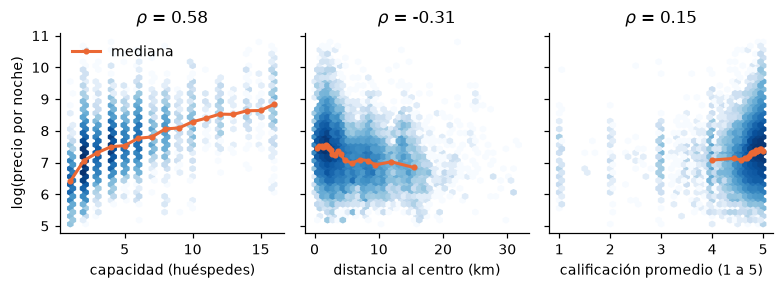

anuncios con calificacion 5: 18.4%; mediana de resenas: 4, contra 47 del resto


In [6]:
ETIQUETAS = {"capacidad": "capacidad (huéspedes)",
             "distancia": "distancia al centro (km)",
             "calificacion": "calificación promedio (1 a 5)"}

fig, ejes = plt.subplots(1, 3, figsize=(7.2, 2.7), sharey=True)
for eje, columna in zip(ejes, PREDICTORES):
    x, y = muestra[columna], muestra["log_precio"]
    eje.hexbin(x, y, gridsize=40, bins="log", cmap="Blues", mincnt=1)
    # Mediana de y en cada valor (o clase) de x: la tendencia sin
    # suponer una forma
    clases = x if columna == "capacidad" else pd.qcut(x, 20,
                                                      duplicates="drop")
    tendencia = muestra.groupby(clases, observed=True).agg(
        x=(columna, "median"), y=("log_precio", "median"))
    eje.plot(tendencia["x"], tendencia["y"], color=NARANJA, lw=2,
             marker="o", ms=3, label="mediana")
    rho = stats.spearmanr(x, y).statistic
    eje.set_title(rf"$\rho$ = {rho:.2f}")
    eje.set_xlabel(ETIQUETAS[columna])
ejes[0].set_ylabel("log(precio por noche)")
ejes[0].legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "Dispersion.pdf", bbox_inches="tight")
plt.show()

perfecta = muestra["calificacion"] == 5
print(f"anuncios con calificacion 5: {perfecta.mean():.1%}; mediana de "
      f"resenas: {muestra.loc[perfecta, 'resenas'].median():.0f}, contra "
      f"{muestra.loc[~perfecta, 'resenas'].median():.0f} del resto")

Lo que se ve:

- **Capacidad**: sube clarísimo, pero cada huésped extra aporta menos que el anterior. La curva es cóncava en log-precio, lo que sugiere usar también el logaritmo de la capacidad.
- **Distancia**: baja rápido en los primeros tres kilómetros y luego se aplana; también parece logarítmica. La mediana va a saltos, porque a la misma distancia del centro hay zonas caras y baratas.
- **Calificación**: casi todo está entre 4.5 y 5, y la relación es débil. Con calificación perfecta hay muchos anuncios nuevos: su mediana de reseñas es de 4, contra 47 del resto, así que su 5 dice poco.

## Pasos 4 y 5: modelo lineal, residuos y ajuste

El modelo que sale directo de la tarea es

$$\text{precio} = \beta_0 + \beta_1\,\text{capacidad} + \beta_2\,\text{distancia} + \beta_3\,\text{calificación} + \varepsilon.$$

Se ajusta por mínimos cuadrados ordinarios, $\hat\beta = (X^\top X)^{-1} X^\top y$, con numpy. Junto a cada $\beta$ van dos errores estándar:

- el **clásico**, que supone errores independientes y de varianza constante;
- el **agrupado por anfitrión**, que no supone ninguna de las dos cosas dentro de un anfitrión. Hace falta porque un mismo anfitrión publica muchos anuncios parecidos con precios fijados por la misma persona: no son observaciones independientes. Los valores $p$ y los intervalos de confianza usan este.

La prueba de Breusch-Pagan revisa si la varianza de los residuos cambia con los predictores; su hipótesis nula es varianza constante.

In [7]:
def ajustar(datos, columnas, respuesta):
    """
    Ajusta un modelo lineal por minimos cuadrados ordinarios.
    Ademas del error estandar clasico calcula el robusto agrupado por
    anfitrion (CR1): los anuncios de un mismo anfitrion no son
    independientes, y el clasico se queda corto. Los valores p usan
    el agrupado

    Inputs:
    -------
    datos: DataFrame con las columnas, la respuesta y host_id
    columnas: Lista de columnas que entran como predictores
    respuesta: Nombre de la columna respuesta

    Returns:
    -------
    dict: Tabla de coeficientes, residuos, ajustados y medidas de ajuste

    """
    X = np.column_stack([np.ones(len(datos)), datos[columnas]])
    y = datos[respuesta].to_numpy()
    n, k = X.shape
    xtx_inv = np.linalg.inv(X.T @ X)
    beta = xtx_inv @ X.T @ y
    ajustados = X @ beta
    residuos = y - ajustados

    s2 = residuos @ residuos / (n - k)
    se_clasico = np.sqrt(np.diag(s2 * xtx_inv))

    # Robusto agrupado: suma por anfitrion de X_g' e_g e_g' X_g
    grupos = datos["host_id"].to_numpy()
    puntaje = pd.DataFrame(X * residuos[:, None]).groupby(grupos).sum()
    medio = puntaje.to_numpy().T @ puntaje.to_numpy()
    g = len(puntaje)
    correccion = g / (g - 1) * (n - 1) / (n - k)
    se = np.sqrt(np.diag(correccion * xtx_inv @ medio @ xtx_inv))
    t = beta / se
    p = 2 * stats.t.sf(np.abs(t), df=g - 1)
    critico = stats.t.ppf(0.975, df=g - 1)

    sct = np.sum((y - y.mean()) ** 2)
    scr = residuos @ residuos
    r2 = 1 - scr / sct

    # Breusch-Pagan en la version de Koenker: regresa e^2 sobre los
    # predictores; n R^2 es chi-cuadrada con k - 1 grados si la
    # varianza es constante
    u = residuos ** 2
    gamma = np.linalg.lstsq(X, u, rcond=None)[0]
    r2_u = 1 - np.sum((u - X @ gamma) ** 2) / np.sum((u - u.mean()) ** 2)
    bp = n * r2_u

    tabla = pd.DataFrame({
        "beta": beta, "EE clasico": se_clasico, "EE agrupado": se,
        "t": t, "p": p,
        "IC 95% inf": beta - critico * se,
        "IC 95% sup": beta + critico * se,
    }, index=["intercepto"] + list(columnas))
    medidas = {"n": n, "anfitriones": g, "R2": r2,
               "R2 ajustada": 1 - (1 - r2) * (n - 1) / (n - k),
               "RMSE": np.sqrt(scr / n), "MAE": np.mean(np.abs(residuos)),
               "asimetria res.": stats.skew(residuos),
               "curtosis res.": stats.kurtosis(residuos),
               "Breusch-Pagan": bp, "p BP": stats.chi2.sf(bp, k - 1)}
    return {"tabla": tabla, "medidas": medidas, "residuos": residuos,
            "ajustados": ajustados, "beta": beta, "columnas": columnas}


def mostrar(modelo):
    """
    Muestra la tabla de coeficientes y las medidas de ajuste.

    Inputs:
    -------
    modelo: Lo que devuelve ajustar

    Returns:
    -------
    None

    """
    display(modelo["tabla"].round(4))
    display(pd.Series(modelo["medidas"]).to_frame("valor").T.round(4))


m0 = ajustar(muestra, PREDICTORES, "precio")
mostrar(m0)

,beta,EE clasico,EE agrupado,t,p,IC 95% inf,IC 95% sup
intercepto,-703.0082,153.9875,235.4541,-2.9858,0.0028,-1164.5426,-241.4737
capacidad,456.3836,5.0919,22.5107,20.2740,0.0000,412.2583,500.5089
distancia,-65.7896,2.8423,5.3348,-12.3321,0.0000,-76.2468,-55.3324
calificacion,290.6248,31.9991,46.4501,6.2567,0.0000,199.5738,381.6758


,n,anfitriones,R2,R2 ajustada,RMSE,MAE,asimetria res.,curtosis res.,Breusch-Pagan,p BP
valor,24763.0,10561.0,0.2631,0.263,1873.1012,884.6832,8.4968,132.0816,403.4554,0.0


### Modelo 0: el precio en pesos

El $R^2$ no es malo, pero los residuos dicen que el modelo está mal planteado. La asimetría y la curtosis son enormes y la prueba de Breusch-Pagan rechaza con mucha holgura la varianza constante. En la gráfica de residuos contra ajustados la nube se abre como embudo, y la Q-Q se despega de la recta en la cola derecha: unos cuantos anuncios carísimos dominan la suma de cuadrados.

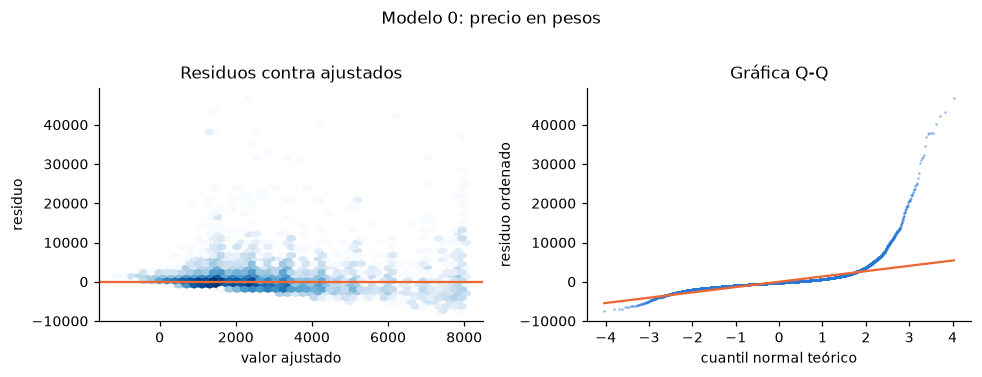

In [8]:
def graficar_residuos(modelo, titulo, archivo=None):
    """
    Residuos contra ajustados y grafica Q-Q de los residuos.

    Inputs:
    -------
    modelo: Lo que devuelve ajustar
    titulo: Titulo de la figura
    archivo: Nombre del PDF en RUTA_FIGURAS, o None para no guardarla

    Returns:
    -------
    None

    """
    residuos = modelo["residuos"]
    fig, ejes = plt.subplots(1, 2, figsize=(9, 3.3))
    ejes[0].hexbin(modelo["ajustados"], residuos, gridsize=45, bins="log",
                   cmap="Blues", mincnt=1)
    ejes[0].axhline(0, color=NARANJA, lw=1.5)
    ejes[0].set_xlabel("valor ajustado")
    ejes[0].set_ylabel("residuo")
    ejes[0].set_title("Residuos contra ajustados")
    (teoricos, ordenados), (pendiente, corte, _) = stats.probplot(residuos)
    ejes[1].plot(teoricos, ordenados, ".", color=AZUL, ms=1.5, alpha=0.4)
    ejes[1].plot(teoricos, pendiente * teoricos + corte, color=NARANJA,
                 lw=1.5)
    ejes[1].set_xlabel("cuantil normal teórico")
    ejes[1].set_ylabel("residuo ordenado")
    ejes[1].set_title("Gráfica Q-Q")
    fig.suptitle(titulo, y=1.02)
    fig.tight_layout()
    if archivo:
        fig.savefig(RUTA_FIGURAS / archivo, bbox_inches="tight")
    plt.show()


graficar_residuos(m0, "Modelo 0: precio en pesos")

### Modelo 1: el logaritmo del precio

Tomar logaritmo del precio ataca las dos cosas a la vez: comprime la cola derecha y vuelve multiplicativos los efectos, que es lo natural para un precio (un huésped extra sube el precio un tanto por ciento, no una cantidad fija de pesos).

,beta,EE clasico,EE agrupado,t,p,IC 95% inf,IC 95% sup
intercepto,6.0670,0.0452,0.1076,56.3705,0.0,5.8560,6.2780
capacidad,0.1637,0.0015,0.0047,34.8923,0.0,0.1545,0.1729
distancia,-0.0405,0.0008,0.0021,-18.8684,0.0,-0.0447,-0.0363
calificacion,0.1798,0.0094,0.0213,8.4598,0.0,0.1381,0.2214


,n,anfitriones,R2,R2 ajustada,RMSE,MAE,asimetria res.,curtosis res.,Breusch-Pagan,p BP
valor,24763.0,10561.0,0.3799,0.3799,0.5503,0.4165,0.3386,2.1167,244.592,0.0


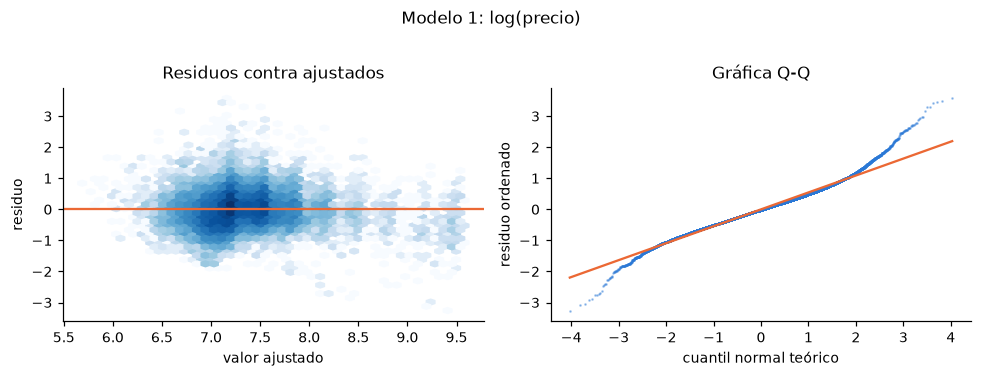

In [9]:
m1 = ajustar(muestra, PREDICTORES, "log_precio")
mostrar(m1)
graficar_residuos(m1, "Modelo 1: log(precio)")

Mucho mejor: el $R^2$ sube de 0.26 a 0.38, la asimetría de los residuos cae de 8.5 a 0.3 y la Q-Q queda casi recta. Falta revisar si la forma de cada predictor es la correcta. Para eso se promedia el residuo dentro de clases de cada predictor; si la forma está bien, el promedio debería quedarse cerca de cero en todas.

In [10]:
def residuo_por_clase(datos, residuos, columna, clases):
    """
    Residuo medio en cada clase de un predictor.
    Si el modelo captura bien la forma de la relacion, el residuo medio
    se queda cerca de cero en todas las clases; un patron sistematico
    dice que falta curvatura

    Inputs:
    -------
    datos: DataFrame con la columna
    residuos: Arreglo de residuos, en el orden de datos
    columna: Predictor a revisar
    clases: Bordes de las clases, o None para usar cada valor

    Returns:
    -------
    DataFrame: Residuo medio y numero de anuncios por clase

    """
    x = datos[columna]
    grupo = x.clip(upper=12) if clases is None else pd.cut(x, clases)
    return (pd.Series(residuos, index=datos.index)
            .groupby(grupo, observed=True)
            .agg(["mean", "count"])
            .rename(columns={"mean": "residuo medio", "count": "anuncios"})
            .round(3).T)


CLASES = {"capacidad": None,
          "distancia": [0, 1, 2, 3, 5, 7, 10, 15, 20, 40],
          "calificacion": [0, 3, 4, 4.5, 4.7, 4.8, 4.9, 5]}
for columna, clases in CLASES.items():
    print(columna)
    display(residuo_por_clase(muestra, m1["residuos"], columna, clases))

capacidad


capacidad,1,2,3,4,5,6,7,8,9,10,11,12
residuo medio,-0.427,0.009,0.069,0.117,0.02,0.075,0.006,-0.049,-0.18,-0.062,-0.095,-0.429
anuncios,1919.000,9948.000,2470.000,5485.000,1383.00,1916.000,318.000,527.000,79.00,236.000,31.000,451.000


distancia


distancia,"(0, 1]","(1, 2]","(2, 3]","(3, 5]","(5, 7]","(7, 10]","(10, 15]","(15, 20]","(20, 40]"
residuo medio,0.044,0.093,-0.001,-0.061,-0.184,-0.06,0.08,-0.005,0.402
anuncios,2769.000,5281.000,4396.000,4692.000,1943.000,2986.00,1941.00,601.000,154.000


calificacion


calificacion,"(0.0, 3.0]","(3.0, 4.0]","(4.0, 4.5]","(4.5, 4.7]","(4.7, 4.8]","(4.8, 4.9]","(4.9, 5.0]"
residuo medio,0.331,0.055,-0.098,-0.129,-0.071,0.005,0.089
anuncios,296.000,668.000,1825.000,3468.000,4126.000,5879.000,8501.000


Los residuos tienen patrón. En capacidad, el modelo se pasa en los extremos (residuo de -0.43 con un huésped y con 12 o más) y se queda corto en medio, que es lo que pasa cuando la relación verdadera es cóncava y se ajusta una recta. En distancia es al revés: residuos positivos cerca y lejos, negativos entre 3 y 10 km, como cuando la relación baja rápido y luego se aplana. Las dispersiones del paso 3 ya lo sugerían, y las dos formas piden un logaritmo.

### Modelo 2: logaritmo también en capacidad y distancia

$$\log(\text{precio}) = \beta_0 + \beta_1 \log(\text{capacidad}) + \beta_2 \log(\text{distancia}) + \beta_3\,\text{calificación} + \varepsilon$$

Con logaritmo en ambos lados, $\beta_1$ y $\beta_2$ son **elasticidades**: el cambio porcentual del precio por cada 1 % de cambio en la variable.

In [11]:
muestra["log_capacidad"] = np.log(muestra["capacidad"])
muestra["log_distancia"] = np.log(muestra["distancia"])
FINALES = ["log_capacidad", "log_distancia", "calificacion"]

m2 = ajustar(muestra, FINALES, "log_precio")
mostrar(m2)
for columna, clases in CLASES.items():
    print(columna)
    display(residuo_por_clase(muestra, m2["residuos"], columna, clases))

,beta,EE clasico,EE agrupado,t,p,IC 95% inf,IC 95% sup
intercepto,5.9592,0.0436,0.1006,59.2156,0.0,5.7619,6.1564
log_capacidad,0.7174,0.0059,0.0135,53.1569,0.0,0.6909,0.7439
log_distancia,-0.1818,0.0036,0.0088,-20.7713,0.0,-0.1990,-0.1646
calificacion,0.1641,0.0091,0.0199,8.2387,0.0,0.1250,0.2031


,n,anfitriones,R2,R2 ajustada,RMSE,MAE,asimetria res.,curtosis res.,Breusch-Pagan,p BP
valor,24763.0,10561.0,0.4254,0.4253,0.5297,0.4015,0.5254,2.236,110.1216,0.0


capacidad


capacidad,1,2,3,4,5,6,7,8,9,10,11,12
residuo medio,-0.058,0.037,-0.022,-0.019,-0.11,-0.019,-0.042,-0.029,-0.086,0.128,0.167,0.208
anuncios,1919.000,9948.000,2470.000,5485.000,1383.00,1916.000,318.000,527.000,79.000,236.000,31.000,451.000


distancia


distancia,"(0, 1]","(1, 2]","(2, 3]","(3, 5]","(5, 7]","(7, 10]","(10, 15]","(15, 20]","(20, 40]"
residuo medio,-0.103,0.082,0.042,-0.001,-0.116,-0.029,0.031,-0.13,0.032
anuncios,2769.000,5281.000,4396.000,4692.000,1943.000,2986.000,1941.000,601.00,154.000


calificacion


calificacion,"(0.0, 3.0]","(3.0, 4.0]","(4.0, 4.5]","(4.5, 4.7]","(4.7, 4.8]","(4.8, 4.9]","(4.9, 5.0]"
residuo medio,0.317,0.068,-0.083,-0.127,-0.076,-0.008,0.095
anuncios,296.000,668.000,1825.000,3468.000,4126.000,5879.000,8501.000


El residuo de capacidad queda mucho más plano; solo los alojamientos de 10 huéspedes o más siguen subestimados, por 0.13 a 0.21. En distancia el residuo zigzaguea: el modelo se pasa en el primer kilómetro, se queda corto entre 1 y 3 km, vuelve a pasarse entre 5 y 7, y así. Eso no lo arregla ninguna transformación de la distancia, porque es geografía: dos colonias a la misma distancia del Ángel pero en direcciones distintas pueden tener precios muy diferentes, y una distancia en línea recta no las distingue. En calificación queda una U: los 296 anuncios con calificación de 3 o menos están más caros de lo que predice el modelo.

Abajo se prueban también términos cuadráticos: calificación$^2$, o distancia y distancia$^2$ en vez del logaritmo. Suben el $R^2$ menos de una centésima y cuestan interpretabilidad, así que el modelo 2 se queda como final.

In [12]:
# Variantes con terminos cuadraticos: cuanto R^2 ganan sobre el modelo 2
muestra["calificacion2"] = muestra["calificacion"] ** 2
muestra["distancia2"] = muestra["distancia"] ** 2
VARIANTES = {
    "modelo 2": FINALES,
    "modelo 2 + calificacion^2": FINALES + ["calificacion2"],
    "distancia + distancia^2 en vez de log": ["log_capacidad", "distancia",
                                               "distancia2", "calificacion"],
}
display(pd.Series({nombre: ajustar(muestra, columnas, "log_precio")
                   ["medidas"]["R2"]
                   for nombre, columnas in VARIANTES.items()},
                  name="R2").round(4).to_frame())

comparacion = pd.DataFrame({
    "Modelo 0: precio": m0["medidas"],
    "Modelo 1: log(precio)": m1["medidas"],
    "Modelo 2: log-log": m2["medidas"],
}).T
display(comparacion[["R2", "R2 ajustada", "RMSE", "asimetria res.",
                     "curtosis res.", "Breusch-Pagan"]].round(4))

,R2
modelo 2,0.4254
modelo 2 + calificacion^2,0.4340
distancia + distancia^2 en vez de log,0.4295


,R2,R2 ajustada,RMSE,asimetria res.,curtosis res.,Breusch-Pagan
Modelo 0: precio,0.2631,0.2630,1873.1012,8.4968,132.0816,403.4554
Modelo 1: log(precio),0.3799,0.3799,0.5503,0.3386,2.1167,244.5920
Modelo 2: log-log,0.4254,0.4253,0.5297,0.5254,2.2360,110.1216


De un modelo al siguiente el $R^2$ sube de 0.26 a 0.43, la asimetría de los residuos cae de 8.5 a menos de 0.6 y el estadístico de Breusch-Pagan baja de 403 a 110. La heterocedasticidad se reduce mucho, aunque no desaparece: la prueba sigue rechazando en el modelo 2. Por eso los errores estándar que se reportan son los agrupados, que no necesitan varianza constante.

### Diagnóstico del modelo final

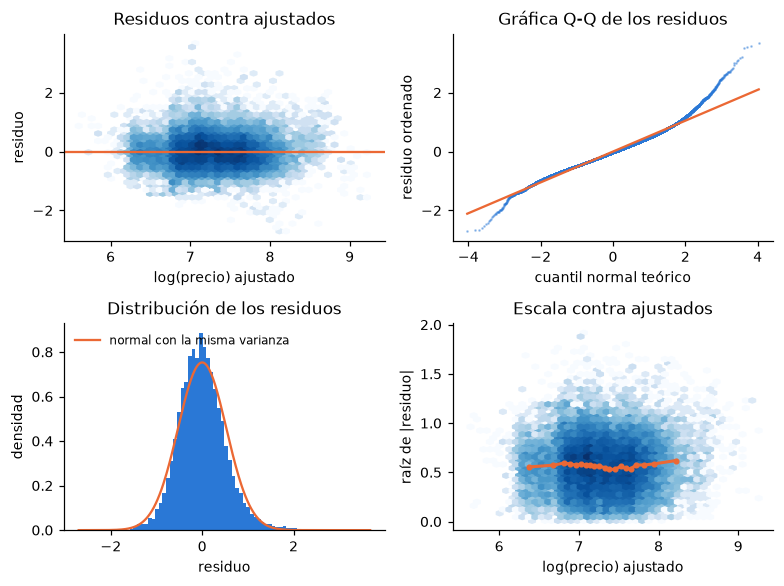

In [13]:
fig, ejes = plt.subplots(2, 2, figsize=(7.2, 5.4))
res, aj = m2["residuos"], m2["ajustados"]

ejes[0, 0].hexbin(aj, res, gridsize=45, bins="log", cmap="Blues",
                  mincnt=1)
ejes[0, 0].axhline(0, color=NARANJA, lw=1.5)
ejes[0, 0].set(xlabel="log(precio) ajustado", ylabel="residuo",
               title="Residuos contra ajustados")

(teoricos, ordenados), (pendiente, corte, _) = stats.probplot(res)
ejes[0, 1].plot(teoricos, ordenados, ".", color=AZUL, ms=1.5, alpha=0.4)
ejes[0, 1].plot(teoricos, pendiente * teoricos + corte, color=NARANJA,
                lw=1.5)
ejes[0, 1].set(xlabel="cuantil normal teórico", ylabel="residuo ordenado",
               title="Gráfica Q-Q de los residuos")

ejes[1, 0].hist(res, bins=80, color=AZUL, density=True)
malla = np.linspace(res.min(), res.max(), 300)
ejes[1, 0].plot(malla, stats.norm.pdf(malla, 0, res.std()), color=NARANJA,
                lw=1.5, label="normal con la misma varianza")
ejes[1, 0].set(xlabel="residuo", ylabel="densidad",
               title="Distribución de los residuos")
ejes[1, 0].legend(frameon=False, fontsize=8, loc="upper left")

# Escala-localizacion: raiz del residuo absoluto contra ajustado. Si
# la varianza es constante, la mediana por clase queda plana
escala = np.sqrt(np.abs(res))
clases = pd.qcut(aj, 20)
tendencia = pd.DataFrame({"aj": aj, "esc": escala}).groupby(
    clases, observed=True).median()
ejes[1, 1].hexbin(aj, escala, gridsize=45, bins="log", cmap="Blues",
                  mincnt=1)
ejes[1, 1].plot(tendencia["aj"], tendencia["esc"], color=NARANJA, lw=2,
                marker="o", ms=3)
ejes[1, 1].set(xlabel="log(precio) ajustado", ylabel="raíz de |residuo|",
               title="Escala contra ajustados")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "Diagnostico.pdf", bbox_inches="tight")
plt.show()

- **Residuos contra ajustados**: la nube está centrada en cero y sin curvatura.
- **Q-Q**: casi recta entre -2 y 2, con colas más pesadas que la normal, sobre todo la derecha: hay anuncios bastante más caros de lo que su tamaño y ubicación predicen.
- **Histograma**: casi simétrico, un poco más picudo que la normal y con la cola derecha más larga (asimetría de 0.5).
- **Escala contra ajustados**: la mediana de $\sqrt{|e|}$ es casi plana y apenas sube en los extremos. Es lo que detecta Breusch-Pagan; con 25 mil anuncios la prueba encuentra diferencias aunque sean pequeñas.

### ¿El ajuste se sostiene fuera de la muestra?

El objetivo es explicar, pero vale la pena revisar que los coeficientes no estén sobreajustados. Se aparta el 20 % de los anuncios, se ajusta con el resto y se mide el error en el 20 % que el modelo no vio.

In [14]:
generador = np.random.default_rng(SEMILLA)
en_prueba = generador.random(len(muestra)) < 0.2
entrena, prueba = muestra[~en_prueba], muestra[en_prueba]
m2_entrena = ajustar(entrena, FINALES, "log_precio")

X_prueba = np.column_stack([np.ones(len(prueba)), prueba[FINALES]])
predicho = X_prueba @ m2_entrena["beta"]
real = prueba["log_precio"].to_numpy()
r2_prueba = 1 - np.sum((real - predicho) ** 2) / np.sum(
    (real - real.mean()) ** 2)
# En pesos: exp(prediccion) estima la mediana del precio dado X
pesos_real, pesos_pred = np.exp(real), np.exp(predicho)
display(pd.DataFrame({
    "entrenamiento": {"anuncios": len(entrena),
                      "R2": m2_entrena["medidas"]["R2"],
                      "RMSE log": m2_entrena["medidas"]["RMSE"]},
    "prueba": {"anuncios": len(prueba), "R2": r2_prueba,
               "RMSE log": np.sqrt(np.mean((real - predicho) ** 2))},
}).T.round(4))
print(f"error absoluto mediano en prueba: "
      f"{np.median(np.abs(pesos_real - pesos_pred)):,.0f} pesos")
print(f"error porcentual absoluto mediano en prueba: "
      f"{np.median(np.abs(pesos_real - pesos_pred) / pesos_real) * 100:.1f} %")
display(m2_entrena["tabla"][["beta"]].T.round(4))

,anuncios,R2,RMSE log
entrenamiento,19834.0,0.4252,0.5294
prueba,4929.0,0.4248,0.5311


error absoluto mediano en prueba: 434 pesos
error porcentual absoluto mediano en prueba: 32.0 %


,intercepto,log_capacidad,log_distancia,calificacion
beta,5.9555,0.7182,-0.1801,0.1651


El $R^2$ de prueba es prácticamente igual al de entrenamiento y los coeficientes casi no cambian: el modelo no está sobreajustado, cosa esperable con cuatro parámetros y 20 mil anuncios. Como predictor es mediocre: el error típico es de alrededor de un tercio del precio. Tiene sentido, porque faltan cosas que pesan mucho, como el tipo de cuarto o la zona exacta.

## Interpretación de los coeficientes

Como la respuesta está en logaritmo, los efectos se leen en porcentaje. Para las elasticidades, multiplicar la variable por un factor $c$ multiplica el precio por $c^{\beta}$; para la calificación, sumarle $\Delta$ multiplica el precio por $e^{\beta_3 \Delta}$.

In [15]:
b = m2["tabla"]
efectos = pd.DataFrame({
    "cambio": ["capacidad +10 %", "capacidad de 2 a 4",
               "distancia +10 %", "distancia de 2 a 8 km",
               "calificacion +0.1", "calificacion de 4.5 a 5"],
    "efecto en el precio (%)": [
        (1.1 ** b.loc["log_capacidad", "beta"] - 1) * 100,
        (2 ** b.loc["log_capacidad", "beta"] - 1) * 100,
        (1.1 ** b.loc["log_distancia", "beta"] - 1) * 100,
        (4 ** b.loc["log_distancia", "beta"] - 1) * 100,
        (np.exp(0.1 * b.loc["calificacion", "beta"]) - 1) * 100,
        (np.exp(0.5 * b.loc["calificacion", "beta"]) - 1) * 100,
    ],
})
display(efectos.round(1))

,cambio,efecto en el precio (%)
0,capacidad +10 %,7.1
1,capacidad de 2 a 4,64.4
2,distancia +10 %,-1.7
3,distancia de 2 a 8 km,-22.3
4,calificacion +0.1,1.7
5,calificacion de 4.5 a 5,8.5


## Entregable

**Ecuación ajustada** ($n = 24{,}763$ anuncios de 10,561 anfitriones):

$$\widehat{\log(\text{precio})} = 5.959 + 0.717\,\log(\text{capacidad}) - 0.182\,\log(\text{distancia}) + 0.164\,\text{calificación}$$

**$\beta$ estimados**, con error estándar agrupado por anfitrión: los tres son distintos de cero con $p < 0.001$ (tabla del modelo 2).

- Capacidad: elasticidad de 0.72. Duplicar la capacidad, de 2 a 4 huéspedes, sube el precio 64 %. Cada huésped extra vale cada vez menos.
- Distancia: elasticidad de -0.18. Pasar de 2 a 8 km del Ángel baja el precio 22 %.
- Calificación: un punto más sube el precio 18 %; en la práctica casi todo está entre 4.5 y 5, y ese medio punto vale 8.5 %. Es el efecto más chico de los tres.

**$R^2$ y error**: $R^2 = 0.425$ en la muestra y también 0.425 en la partición de prueba. La raíz del error cuadrático medio es de 0.53 en logaritmo; en pesos, el error absoluto mediano en prueba es de 434 pesos, el 32 % del precio.

**Diagnóstico**: residuos casi simétricos y casi normales en log-precio, con la cola derecha algo pesada; sin curvatura en capacidad; heterocedasticidad moderada, que se maneja con errores estándar agrupados; patrón geográfico en la distancia que el modelo no captura.

**Gráfica**: la figura de diagnóstico del modelo 2 (`figuras/Diagnostico.pdf`).

**Límites de la interpretación**:

- Es un estudio observacional. Los $\beta$ son asociaciones, no efectos causales: ampliar un departamento no garantiza cobrar 64 % más.
- Faltan variables que importan, sobre todo el tipo de cuarto y la alcaldía. Si están correlacionadas con las incluidas, los $\beta$ cargan parte de su efecto; un cuarto privado tiene menos capacidad y es más barato por ambas razones.
- La distancia en línea recta resume mal la geografía, como mostraron los residuos.
- Solo entran anuncios con reseñas. Los nuevos o los que nunca se rentaron quedan fuera, y nada garantiza que el modelo valga para ellos.
- El precio es el anunciado para las fechas que cotizó el corte, no lo que pagó un huésped, y es un solo corte de septiembre.
- Airbnb mueve las coordenadas publicadas hasta unos 150 m para proteger al anfitrión; para la distancia al centro el efecto es pequeño.